# Figure 5 · Xoay không gian đặc trưng

**Nguồn chính** · Kết quả từng lượt do tác giả công bố. Notebook chạy lại phép phân tích và vẽ hình bằng Python. Lần mở đầu cần Internet để tải và đối chiếu SHA-256.

## Cách đọc thí nghiệm

Tách từng nhánh giữ toàn bộ hoặc loại 50% đặc trưng trước khi Gaussian hóa và xoay. So sánh trước và sau xoay ở hạng 20 bằng boxplot qua 30 lần xáo, default-first và chọn theo validation. Hình lấy hai nhánh từ dữ liệu công bố, gồm cả nhánh mà script vẽ chính có chú thích bật thủ công.

In [1]:
from pathlib import Path
import sys

root = next(folder for folder in (Path.cwd(), *Path.cwd().parents)
            if (folder / "src/analysis.py").is_file())
sys.path.insert(0, str(root))
from IPython.display import Image, display
import matplotlib.pyplot as plt
from src.analysis import analyze
from src.author_data import SOURCES, prepare
from src.plots import export, export_project

source = "ablations"
cache = prepare(source)
print("SHA-256 nguồn:", SOURCES[source].sha256)

SHA-256 nguồn: 25314ccb2d138dae43fd23840f729f62fba0b5f5ab559aeb3727403dedb4e429


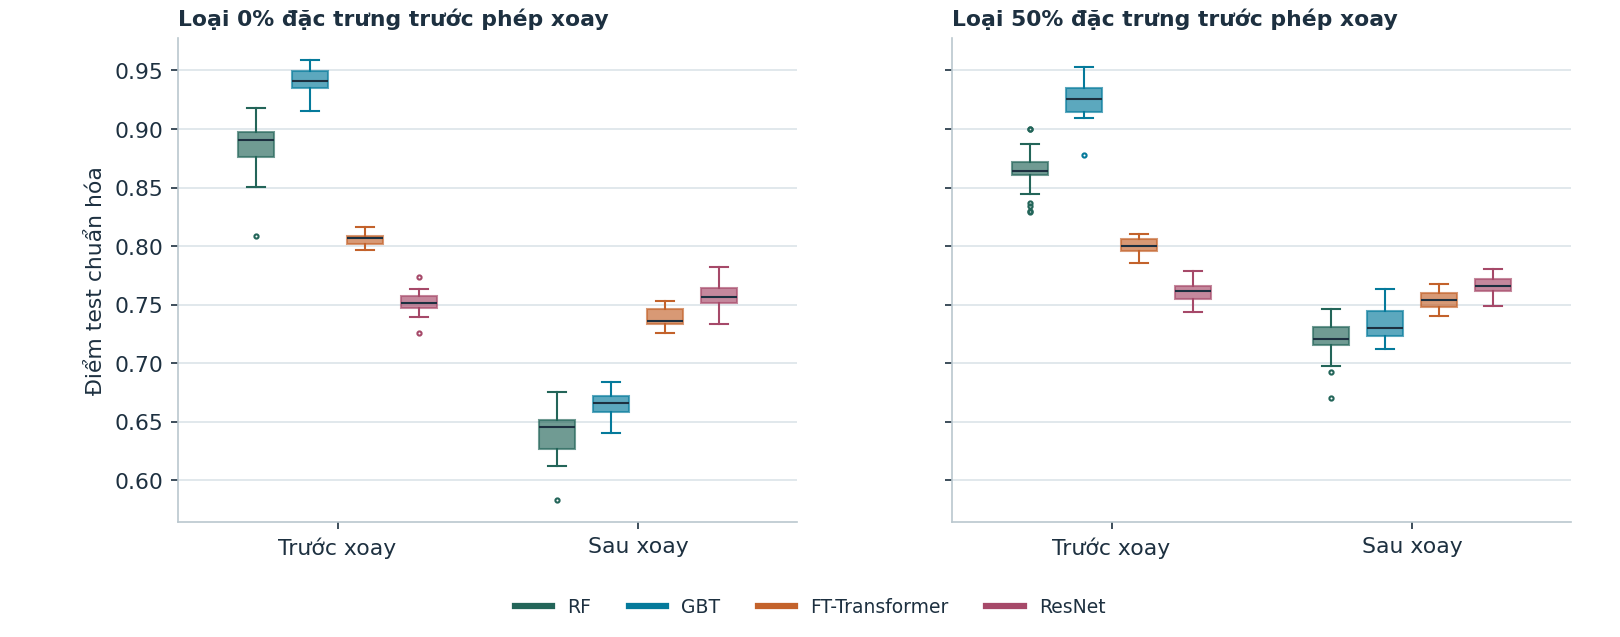

In [2]:
figure_number = 5
scores = analyze(figure_number)
chart = export(figure_number, scores)
plt.close(chart)
display(Image(filename=str(root / "figures" / f"figure_{figure_number:02d}.png")))

## Một số giá trị đứng sau biểu đồ

In [3]:
display(scores.head(8).round(5))

,model_name,shuffle,transform__2__deactivated,score,removed
0,FT Transformer,1,False,0.72972,0.0
1,FT Transformer,1,True,0.80895,0.0
2,FT Transformer,2,False,0.73585,0.0
3,FT Transformer,2,True,0.81055,0.0
4,FT Transformer,3,False,0.72639,0.0
5,FT Transformer,3,True,0.80862,0.0
6,FT Transformer,4,False,0.74394,0.0
7,FT Transformer,4,True,0.80108,0.0


## Đối chứng do nhóm tự train

Đối chứng tự train dùng cấu hình mặc định của 16 bộ dữ liệu số. Có 762/768 fit lõi đã kiểm chứng và 381 cặp đo chênh lệch. Biểu đồ dưới hiển thị trung bình chênh lệch accuracy trên các cặp có đầu ra.

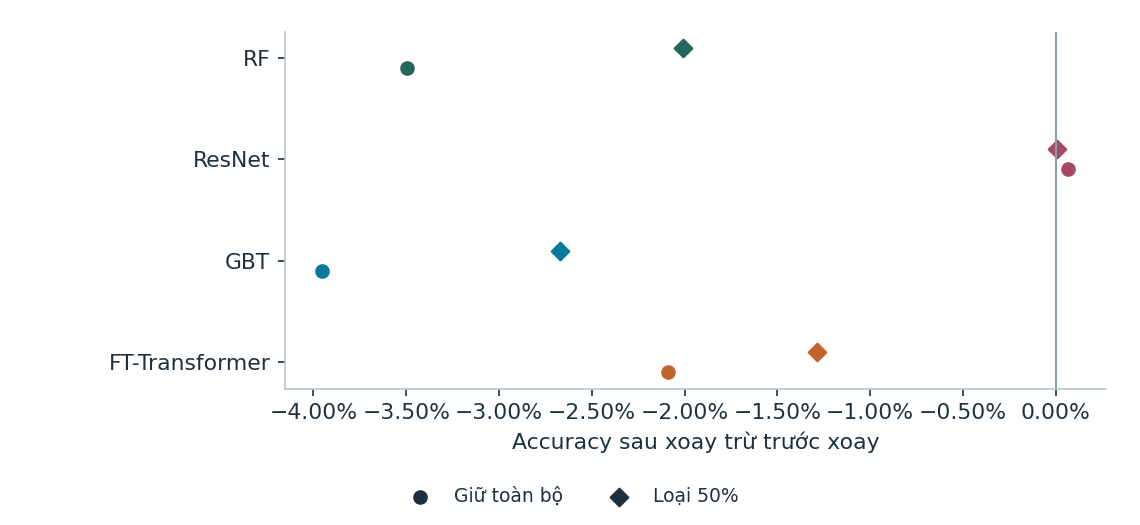

In [4]:
chart = export_project(figure_number)
plt.close(chart)
display(Image(filename=str(root / "figures" / f"figure_{figure_number:02d}_v2.png")))

## Quy trình train trong repo tác giả

**Minh họa quy trình, không có fit mới ở notebook này.** Điểm vào: `src/launch_benchmarks/launch_xps.py · random_rotation`. Chọn nhánh bỏ 0% hoặc 50% đặc trưng; Gaussian hóa; bật hoặc tắt xoay; train và so sánh điểm trên cùng protocol.

Nếu tái chạy độc lập, dùng cấu hình đầy đủ của đúng model, task và điều kiện từ CSV nguồn. Repo gốc có lệnh chuẩn bị môi trường, launcher và `train_model_on_config`; khóa phiên bản source trước khi chạy. 

### Ví dụ cấu hình đã công bố

Các giá trị dưới đây trích từ dòng đầu tiên của GBT trong từng nhánh, theo thứ tự CSV. File lịch sử dùng tên bộ dữ liệu và loader `real_data`. Launcher pin hiện tại dùng OpenML task ID và `openml_no_transform`, nên cần đối chiếu đầu vào khi chạy lại ví dụ.

In [5]:
import json
import pandas as pd
published = json.loads((root / "evidence/published_config_examples.json").read_text(encoding="utf-8"))
names = ('random_rotation',)
display(pd.DataFrame({name: published["examples"][name]["settings"] for name in names}).fillna("—"))

,random_rotation
data__keyword,bank-marketing
data__method_name,real_data
data__regression,0
max_train_samples,10000
model__learning_rate,0.00371332807029818
model__loss,exponential
model__min_samples_leaf,4
model__min_samples_split,2
model__n_estimators,11
model__subsample,0.9625781885297454


## Nguồn

- [Paper NeurIPS 2022](https://papers.neurips.cc/paper_files/paper/2022/hash/0378c7692da36807bdec87ab043cdadc-Abstract-Datasets_and_Benchmarks.html)
- [Repo tác giả, commit đã đối chiếu](https://github.com/LeoGrin/tabular-benchmark/tree/9d54cf53d9fd3159e367e70a00005f4fcbf2c79d)
